# Inverse Operators in Coefficient Space

**Learning Objectives**
- Pose an inverse problem as a map from output coefficients $\beta$ to input coefficients $\alpha$ between two learned bases
- Read the uniqueness and the stability of an inverse from the singular values of the forward map in coefficient space
- Build an invertible network from affine coupling layers and explain why its inverse is exact
- Sample the inputs consistent with an observation from a conditional normalizing flow
- Compare inverse models by input error and re-simulation error

[![Open in Colab](https://img.shields.io/badge/Open%20in-Colab-F9AB00?style=flat-square&logo=googlecolab)](https://colab.research.google.com/github/kks32-courses/sciml/blob/main/docs/03-function-encoder/03-fe-inverse.ipynb) [![View Slides](https://img.shields.io/badge/View-Presentation-yellow?style=flat-square&logo=googleslides&logoColor=white)](https://raw.githubusercontent.com/kks32-courses/sciml/main/docs/03-function-encoder/b2b.pdf)

This notebook follows Thorpe, Tretiakov, Roy Sarkar, Kumar, and Topcu, "Learning Generalizable Neural Operators for Inverse Problems" (arXiv:2512.18120), on the simplest operators there are.
The paper learns one basis for the input functions and one for the output functions, and then learns the inverse as a map between their coefficient vectors (Figure 1 of the paper).
With the representation separated from the inverse, one framework holds deterministic, invertible, and probabilistic inverse models.
We compare four of them on integration, whose inverse is unique, and on differentiation, whose inverse is not.

In [1]:
import time
import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from matplotlib.colors import to_rgba

torch.set_default_dtype(torch.float64)
torch.manual_seed(0)
rng = np.random.default_rng(0)
device = torch.device("cpu")
t_start = time.time()
print(f"torch {torch.__version__}, dtype {torch.get_default_dtype()}, device {device}")

torch 2.8.0, dtype torch.float64, device cpu


## Two inverse problems on one family of functions

Every input is a smooth random function on $[0, 1]$,

$$f(x) = a_0 + \sum_{j=1}^{6} a_j \sin(j \pi x),$$

with seven coefficients $a_0, \dots, a_6$ drawn uniformly from $[-1, 1]$.
Problem A observes $u = T_A f$ with $u(x) = \int_0^x f(s)\, ds$, and its inverse is differentiation, $f = u'$.
This inverse is unique and unstable, because a noise component $\epsilon \sin(k \pi x)$ in $u$ becomes $k \pi \epsilon \cos(k \pi x)$ in $f$.
Problem B observes $u = T_B f = f'$, and its inverse is integration with an unknown constant, because $f$ and $f + c$ have the same derivative for every $c$.
Both problems use the same 2000 training and 400 test inputs on $m = 100$ grid points.
The training pairs are noise free, and at test time we add Gaussian noise of standard deviation 0.01 to the observed $u$.

In [2]:
m, n_train, n_test, sigma = 100, 2000, 400, 0.01
x = np.linspace(0, 1, m)
j = np.arange(1, 7)[:, None]
S, C = np.sin(np.pi * j * x), np.cos(np.pi * j * x)    # (6, m)

def make_data(n):
    a = rng.uniform(-1, 1, (n, 7))                       # a[:, 0] is the constant a_0
    f = a[:, :1] + a[:, 1:] @ S
    uA = a[:, :1] * x + a[:, 1:] @ ((1 - C) / (np.pi * j))   # Problem A: integral of f from 0 to x
    uB = a[:, 1:] @ (np.pi * j * C)                      # Problem B: f'
    return a, f, uA, uB

a_tr, f_tr, uA_tr, uB_tr = make_data(n_train)
a_te, f_te, uA_te, uB_te = make_data(n_test)
u_true = {"A": uA_te, "B": uB_te}
u_obs = {p: u + sigma * rng.standard_normal(u.shape) for p, u in u_true.items()}   # noise at test time only

rms = lambda v: np.sqrt(np.mean(v ** 2))
print(f"{n_train} training and {n_test} test functions on {m} grid points")
print(f"rms of f {rms(f_tr):.3f}, of u_A {rms(uA_tr):.3f}, of u_B {rms(uB_tr):.3f}, noise std {sigma}")

2000 training and 400 test functions on 100 grid points
rms of f 1.138, of u_A 0.417, of u_B 12.348, noise std 0.01


## Function encoders for the input and output spaces

A function encoder represents a function by $k$ learned basis functions and least-squares coefficients,

$$\hat f(x) = \sum_{j=1}^{k} \alpha_j \psi_j(x), \qquad \alpha = \left(\tfrac{1}{m} \Psi^\top \Psi + \lambda I\right)^{-1} \tfrac{1}{m} \Psi^\top f, \qquad \Psi_{ij} = \psi_j(x_i),$$

with $k = 8$ and $\lambda = 10^{-6}$.
Training follows Part 3 of the function-encoder notebook, with the norm regularizer $0.1 \sum_j (\|\psi_j\|^2 - 1)^2$ and 6000 Adam steps.
One encoder serves the inputs of both problems, and the outputs $u$ of Problem A and $f'$ of Problem B get one encoder each, with basis $\phi_j$ and coefficients $\beta$.
The learned basis functions cancel each other, and the coefficients of inputs with rms 1.138 have standard deviation 8.40.
After training we replace each basis by an orthonormal basis of the same span, $\Psi \to \Psi R^{-1}$ with $\tfrac{1}{m} \Psi^\top \Psi = R^\top R$, and the standard deviation drops to 0.39.
In the new coordinates $\|\alpha\|$ equals the grid $L^2$ norm of $\hat f$, so a squared error between coefficient vectors is a squared error between functions.

Every inverse model maps $\beta \in \mathbb{R}^8$ to $\alpha \in \mathbb{R}^8$, as in Figure 1 of the paper.
The observed $u$ gives $\beta$ by least squares, the inverse model gives $\alpha$, and the input basis gives $\hat f = \sum_j \alpha_j \psi_j$.
The input error is $\|\hat f - f\| / \|f\|$ on the grid.
The re-simulation error is $\|T \hat f - u_{\text{obs}}\| / \|u_{\text{obs}}\|$, the metric of Table 1 of the paper, and it needs no knowledge of the true $f$.
We apply the exact $T$ to $\hat f$, where the paper uses a separately trained forward model.

In [3]:
k, lam = 8, 1e-6
xt = torch.tensor(x)

class BasisNet(nn.Module):
    """One MLP with k outputs, psi(x) = (psi_1(x), ..., psi_k(x))."""
    def __init__(self, k, hidden=64):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(1, hidden), nn.Tanh(), nn.Linear(hidden, hidden), nn.Tanh(), nn.Linear(hidden, k))

    def forward(self, x):
        return self.net(2 * x.unsqueeze(-1) - 1)

def ls_coefficients(Phi, Y):
    """Ridge least squares for every row of Y (n, m) in the basis Phi (m, k)."""
    G = Phi.T @ Phi / Phi.shape[0]
    return torch.linalg.solve(G + lam * torch.eye(Phi.shape[1]), Phi.T @ Y.T / Phi.shape[0]).T

def train_encoder(F, steps=6000, batch=100, lr=1e-2):
    torch.manual_seed(0)
    net = BasisNet(k)
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    F = torch.tensor(F)
    power = F.pow(2).mean()
    for step in range(steps):
        Y = F[torch.randint(0, len(F), (batch,))]
        Phi = net(xt)
        recon = ls_coefficients(Phi, Y) @ Phi.T
        loss = ((recon - Y) ** 2).mean() / power + 0.1 * ((Phi.pow(2).mean(0) - 1) ** 2).sum()
        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()
    return net

t0 = time.time()
encoders = {"f": train_encoder(f_tr), "uA": train_encoder(uA_tr), "uB": train_encoder(uB_tr)}
with torch.no_grad():
    raw = {name: net(xt).numpy() for name, net in encoders.items()}
print(f"three encoders trained in {time.time() - t0:.1f} s")

# orthonormalize each basis on the grid: G = R^T R, new basis Phi R^{-1}
R = {name: np.linalg.cholesky(P.T @ P / m).T for name, P in raw.items()}
basis = {name: raw[name] @ np.linalg.inv(R[name]) for name in raw}

def coef(name, Y, B=None):
    return ls_coefficients(torch.tensor(basis[name] if B is None else B), torch.tensor(Y)).numpy()

print(f"std of the coefficients of f: raw basis {coef('f', f_tr, raw['f']).std(0).mean():.2f}, orthonormal basis {coef('f', f_tr).std(0).mean():.2f}")
for name, Y in [("f", f_te), ("uA", uA_te), ("uB", uB_te)]:
    rec = coef(name, Y) @ basis[name].T
    err = np.mean(np.linalg.norm(rec - Y, axis=1) / np.linalg.norm(Y, axis=1))
    print(f"encoder for {name:2s}: test MSE {np.mean((rec - Y) ** 2):.2e}, relative L2 error {err:.2e}")

alpha_tr = coef("f", f_tr)
beta_tr = {"A": coef("uA", uA_tr), "B": coef("uB", uB_tr)}         # clean u for training
beta_te = {"A": coef("uA", u_obs["A"]), "B": coef("uB", u_obs["B"])}  # noisy u for testing

three encoders trained in 11.3 s
std of the coefficients of f: raw basis 8.40, orthonormal basis 0.39
encoder for f : test MSE 4.29e-06, relative L2 error 1.78e-03
encoder for uA: test MSE 3.75e-07, relative L2 error 2.15e-03
encoder for uB: test MSE 2.09e-04, relative L2 error 1.18e-03


## A linear inverse and the forward matrix

The simplest inverse model is a matrix $W$ fitted by ridge regression on the $N = 2000$ training pairs (Supplementary B.1.1 of the paper),

$$W = \arg\min_W \frac{1}{N} \sum_{n=1}^{N} \|W \beta_n - \alpha_n\|^2 + \lambda \|W\|_F^2 .$$

Least squares makes $W \beta$ the best linear estimate of the conditional mean $E[\alpha \mid \beta]$.
The same regression in the other direction gives the forward matrix $A$ with $\beta \approx A \alpha$.
When $\beta_n = A \alpha_n$ holds for every pair, the normal equations give $W = C A^\top (A C A^\top + \lambda I)^{-1}$ with $C = \frac{1}{N} \sum_n \alpha_n \alpha_n^\top$.
This is the Tikhonov-regularized inverse of $A$ with the covariance of the training coefficients in place of the identity, and for $C = I$ it reduces to $(A^\top A + \lambda I)^{-1} A^\top$.
A deterministic model assumes a unique and stable inverse, and the singular values of $A$ test both assumptions.

In [4]:
def ridge(X, Y, lam=1e-6):
    """W minimizing the mean of ||W x_n - y_n||^2 plus lam ||W||^2, rows of X and Y are x_n and y_n."""
    return np.linalg.solve(X.T @ X / len(X) + lam * np.eye(X.shape[1]), X.T @ Y / len(X)).T

C_alpha = alpha_tr.T @ alpha_tr / n_train
W, A = {}, {}
for p in "AB":
    W[p] = ridge(beta_tr[p], alpha_tr)       # inverse map, beta -> alpha
    A[p] = ridge(alpha_tr, beta_tr[p])       # forward map, alpha -> beta
    W_tik = C_alpha @ A[p].T @ np.linalg.inv(A[p] @ C_alpha @ A[p].T + 1e-6 * np.eye(k))
    print(f"Problem {p}: ||W - C A^T (A C A^T + lam I)^-1|| / ||W|| = {np.linalg.norm(W[p] - W_tik) / np.linalg.norm(W[p]):.1e}")

# the training coefficients fill a 7-dimensional subspace of R^8, spanned by the columns of Q
U, s_data, _ = np.linalg.svd(alpha_tr.T, full_matrices=False)
print(f"singular values of the training coefficients: {np.array2string(s_data / np.sqrt(n_train), precision=2)}")
Q = U[:, :7]

# exact singular values of T on the span of 1, sin(pi x), ..., sin(6 pi x), in the grid L2 norm
E = np.vstack([np.ones(m), S]).T
TE = {"A": np.vstack([x, (1 - C) / (np.pi * j)]).T, "B": np.vstack([np.zeros(m), np.pi * j * C]).T}
_, R_E = np.linalg.qr(E / np.sqrt(m))
sv = {}
for p in "AB":
    sv[p] = np.linalg.svd(A[p] @ Q, compute_uv=False)
    sv_exact = np.linalg.svd(TE[p] / np.sqrt(m) @ np.linalg.inv(R_E), compute_uv=False)
    print(f"Problem {p}, singular values of A: {np.array2string(sv[p], precision=4)}")
    print(f"Problem {p}, exact operator      : {np.array2string(sv_exact, precision=4)}")

rel = lambda Y, Yt: np.mean(np.linalg.norm(Y - Yt, axis=1) / np.linalg.norm(Yt, axis=1))
f_hat = lambda alpha: alpha @ basis["f"].T
beta_clean = coef("uA", uA_te)
print(f"Problem A, predicted error from noise: sigma (sum 1/s_i^2)^(1/2) / sqrt(m) / rms(f) = {sigma * np.sqrt(np.sum(sv['A'] ** -2.0)) / np.sqrt(m) / rms(f_te):.3f}")
for lam_W in [1e-8, 1e-6, 1e-4, 1e-2]:
    W_lam = ridge(beta_tr["A"], alpha_tr, lam_W)
    print(f"Problem A, linear inverse, lambda = {lam_W:.0e}: input error {rel(f_hat(beta_clean @ W_lam.T), f_te):.2e} from clean u, {rel(f_hat(beta_te['A'] @ W_lam.T), f_te):.2e} from noisy u")
fd = lambda U: np.gradient(U, x, axis=1)
print(f"Problem A, finite differences on the grid: input error {rel(fd(uA_te), f_te):.2e} from clean u, {rel(fd(u_obs['A']), f_te):.2e} from noisy u")

preds = {p: {"linear": beta_te[p] @ W[p].T} for p in "AB"}

Problem A: ||W - C A^T (A C A^T + lam I)^-1|| / ||W|| = 6.0e-05
Problem B: ||W - C A^T (A C A^T + lam I)^-1|| / ||W|| = 1.1e-04
singular values of the training coefficients: [6.76e-01 4.29e-01 4.15e-01 4.01e-01 3.99e-01 3.90e-01 9.49e-02 2.84e-16]
Problem A, singular values of A: [0.6294 0.2096 0.1259 0.0896 0.0698 0.0566 0.0406]
Problem A, exact operator      : [0.6294 0.2096 0.1259 0.0896 0.0698 0.0566 0.0407]
Problem B, singular values of A: [2.1953e+01 1.9042e+01 1.2689e+01 1.2628e+01 6.3433e+00 6.2387e+00
 4.0604e-15]
Problem B, exact operator      : [21.9549 19.0425 12.689  12.6283  6.3433  6.2389  0.    ]
Problem A, predicted error from noise: sigma (sum 1/s_i^2)^(1/2) / sqrt(m) / rms(f) = 0.032
Problem A, linear inverse, lambda = 1e-08: input error 1.78e-03 from clean u, 3.30e-02 from noisy u
Problem A, linear inverse, lambda = 1e-06: input error 5.02e-03 from clean u, 3.26e-02 from noisy u
Problem A, linear inverse, lambda = 1e-04: input error 1.08e-01 from clean u, 1.10e-01 f

The printed $W$ and $C A^\top (A C A^\top + \lambda I)^{-1}$ agree to a relative difference of $6.0 \times 10^{-5}$ on Problem A.
The training coefficients fill a seven-dimensional subspace of $\mathbb{R}^8$, because the family has seven parameters, and the singular values are those of $A$ on that subspace.
For Problem A they match the exact singular values of integration on the span of $1, \sin(\pi x), \dots, \sin(6 \pi x)$, and they decay from 0.6294 to 0.0406.
Noise of standard deviation $\sigma$ on $m$ grid points puts a component of size $\sigma / \sqrt{m}$ on each unit direction, and the inverse multiplies the component along singular direction $i$ by $1 / s_i$.
The predicted error in $f$ is $\sigma (\sum_i s_i^{-2})^{1/2} / \sqrt{m}$, which is 0.032 relative to the rms of $f$, and the linear inverse with $\lambda = 10^{-8}$ measures $3.30 \times 10^{-2}$.
A larger ridge removes the high modes of $f$ along with the noise, and at $\lambda = 10^{-4}$ the error is $1.08 \times 10^{-1}$ from clean $u$ and $1.10 \times 10^{-1}$ from noisy $u$.
Finite differences of the noisy $u$ on the grid give $6.94 \times 10^{-1}$, because the projection onto eight basis functions removes most of the noise before any inverse acts, the denoising the paper reports in Section 2.3.

For Problem B six singular values match those of differentiation, and the seventh is $4.1 \times 10^{-15}$ where the exact value is 0.
Differentiation sends the constant function to zero, so no observation of $f'$ determines $a_0$.
The conditional mean of $a_0$ given $f'$ is 0, because $a_0$ is independent of the other coefficients, and $W$ returns that mean.

## A nonlinear inverse map

The MLP replaces $W$ by a network $\alpha = g_\theta(\beta)$ with two hidden layers of width 64 and tanh activations, trained on the mean squared error

$$\min_\theta \frac{1}{N} \sum_{n=1}^{N} \|g_\theta(\beta_n) - \alpha_n\|^2 .$$

It makes the assumption of the linear model, a unique and stable inverse, and it can represent a nonlinear one.
Over all functions of $\beta$ the minimizer of the mean squared error is the conditional mean $E[\alpha \mid \beta]$, so on Problem B the MLP also returns one point among the consistent inputs.
This network and the two that follow standardize each coordinate of $\alpha$ and $\beta$ with its training mean and standard deviation.
All three train for 3000 Adam steps on batches of 500 pairs.

In [5]:
mean_a, std_a = alpha_tr.mean(0), alpha_tr.std(0)
norm_a = lambda v: torch.tensor((v - mean_a) / std_a)
unnorm_a = lambda t: t.detach().numpy() * std_a + mean_a
norm_b = {p: (lambda v, p=p: torch.tensor((v - beta_tr[p].mean(0)) / beta_tr[p].std(0))) for p in "AB"}

def mlp(n_in, n_out, hidden=64):
    return nn.Sequential(nn.Linear(n_in, hidden), nn.Tanh(), nn.Linear(hidden, hidden), nn.Tanh(), nn.Linear(hidden, n_out))

def fit(model, loss_fn, steps=3000, batch=500, lr=1e-3):
    """Adam with cosine decay on random batches of the training indices; returns the last loss."""
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    for step in range(steps):
        loss = loss_fn(torch.randint(0, n_train, (batch,)))
        opt.zero_grad()
        loss.backward()
        opt.step()
        sched.step()
    return loss.item()

a_n = norm_a(alpha_tr)
for p in "AB":
    b_n = norm_b[p](beta_tr[p])
    torch.manual_seed(0)
    net = mlp(k, k)
    t0 = time.time()
    loss = fit(net, lambda i: ((net(b_n[i]) - a_n[i]) ** 2).mean())
    preds[p]["MLP"] = unnorm_a(net(norm_b[p](beta_te[p])))
    print(f"Problem {p}, MLP: final training loss {loss:.2e}, {time.time() - t0:.1f} s")

Problem A, MLP: final training loss 6.14e-04, 1.9 s


Problem B, MLP: final training loss 1.30e-01, 1.9 s


## Invertible neural networks

An invertible network builds a bijection $T \colon \alpha \mapsto \beta$ from affine coupling layers (Supplementary B.1.3 of the paper).
Each layer splits its input into halves $x_1$ and $x_2$, keeps $x_1$, and scales and shifts $x_2$ by functions of $x_1$,

$$y_1 = x_1, \qquad y_2 = x_2 \odot e^{s(x_1)} + t(x_1),$$

where $s$ and $t$ are the outputs of one small MLP and $\odot$ multiplies entry by entry.
The inverse is exact because the kept half reaches the output unchanged, so $s(y_1)$ and $t(y_1)$ can be recomputed and undone, $x_2 = (y_2 - t(y_1)) \odot e^{-s(y_1)}$.
The MLP itself is never inverted, so it can be any network.
Four layers alternate the kept half, and training minimizes $\|T(\alpha) - \beta\|^2 + \|T^{-1}(\beta) - \alpha\|^2$, as in Equation 36 of the paper.
The first figure below draws one layer in both directions, and the second draws the stack.
A bijection assumes a one-to-one inverse, which holds for Problem A and fails for Problem B, where every line $\{f + c\}$ maps to one $u$.

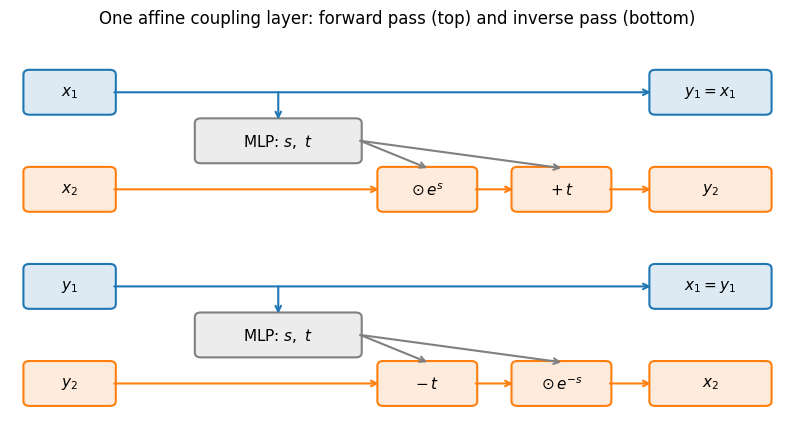

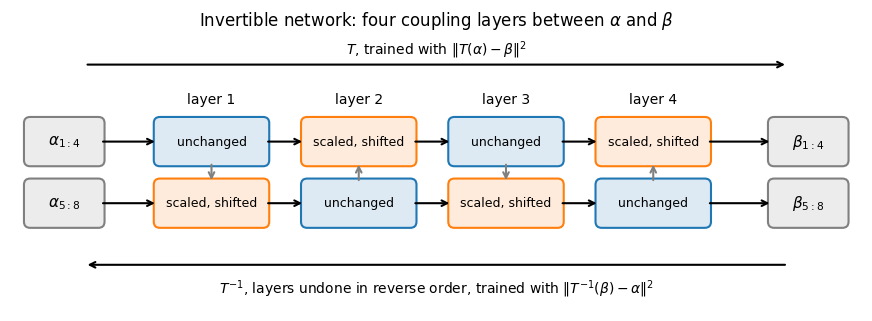

In [6]:
def box(ax, cx, cy, w, h, text, color="gray", fontsize=11):
    ax.add_patch(FancyBboxPatch((cx - w / 2, cy - h / 2), w, h, boxstyle="round,pad=0.02,rounding_size=0.08",
                                fc=to_rgba(color, 0.15), ec=color, lw=1.5))
    ax.text(cx, cy, text, ha="center", va="center", fontsize=fontsize)

def arrow(ax, p, q, text=None, color="black", dx=0.0, dy=0.12, ls="-"):
    ax.annotate("", xy=q, xytext=p, arrowprops=dict(arrowstyle="->", color=color, lw=1.5, ls=ls, shrinkA=0, shrinkB=0))
    if text:
        ax.text((p[0] + q[0]) / 2 + dx, (p[1] + q[1]) / 2 + dy, text, ha="center", va="bottom", fontsize=10)

def blank(figsize, xlim, ylim, title):
    fig, ax = plt.subplots(figsize=figsize)
    ax.set_xlim(*xlim)
    ax.set_ylim(*ylim)
    ax.axis("off")
    ax.set_title(title)
    return fig, ax

# one affine coupling layer, forward (top) and inverse (bottom)
fig, ax = blank((10, 5.2), (0, 10.4), (0, 6.6), "One affine coupling layer: forward pass (top) and inverse pass (bottom)")
for top, bot, a, b, ops, out1, out2 in [(5.6, 4.0, "$x_1$", "$x_2$", [r"$\odot\, e^{s}$", r"$+\, t$"], "$y_1 = x_1$", "$y_2$"),
                                         (2.4, 0.8, "$y_1$", "$y_2$", [r"$-\, t$", r"$\odot\, e^{-s}$"], "$x_1 = y_1$", "$x_2$")]:
    box(ax, 0.8, top, 1.2, 0.7, a, "tab:blue")
    box(ax, 0.8, bot, 1.2, 0.7, b, "tab:orange")
    box(ax, 9.4, top, 1.6, 0.7, out1, "tab:blue")
    box(ax, 9.4, bot, 1.6, 0.7, out2, "tab:orange")
    arrow(ax, (1.4, top), (8.6, top), color="tab:blue")
    box(ax, 3.6, (top + bot) / 2, 2.2, 0.7, r"MLP: $s,\ t$", "gray")
    arrow(ax, (3.6, top), (3.6, (top + bot) / 2 + 0.35), color="tab:blue")
    box(ax, 5.6, bot, 1.3, 0.7, ops[0], "tab:orange")
    box(ax, 7.4, bot, 1.3, 0.7, ops[1], "tab:orange")
    arrow(ax, (1.4, bot), (4.95, bot), color="tab:orange")
    arrow(ax, (6.25, bot), (6.75, bot), color="tab:orange")
    arrow(ax, (8.05, bot), (8.6, bot), color="tab:orange")
    arrow(ax, (4.7, (top + bot) / 2), (5.6, bot + 0.35), color="gray")
    arrow(ax, (4.7, (top + bot) / 2), (7.4, bot + 0.35), color="gray")
plt.show()

# the stack of four coupling layers between alpha and beta
fig, ax = blank((11, 3.6), (0, 11), (0, 3.6), "Invertible network: four coupling layers between $\\alpha$ and $\\beta$")
lanes = (2.2, 1.4)
box(ax, 0.7, lanes[0], 1.0, 0.6, r"$\alpha_{1:4}$")
box(ax, 0.7, lanes[1], 1.0, 0.6, r"$\alpha_{5:8}$")
box(ax, 10.3, lanes[0], 1.0, 0.6, r"$\beta_{1:4}$")
box(ax, 10.3, lanes[1], 1.0, 0.6, r"$\beta_{5:8}$")
xs = [2.6, 4.5, 6.4, 8.3]
for i, cx in enumerate(xs):
    changed = 1 if i % 2 == 0 else 0
    for lane in (0, 1):
        box(ax, cx, lanes[lane], 1.45, 0.6, "scaled, shifted" if lane == changed else "unchanged",
            "tab:orange" if lane == changed else "tab:blue", fontsize=9)
    ax.text(cx, 2.7, f"layer {i + 1}", ha="center", fontsize=10)
    arrow(ax, (cx, lanes[1 - changed] + (-0.3 if changed else 0.3)), (cx, lanes[changed] + (0.3 if changed else -0.3)), color="gray")
for lane in (0, 1):
    for x0, x1 in zip([1.2] + [c + 0.73 for c in xs], [c - 0.73 for c in xs] + [9.8]):
        arrow(ax, (x0, lanes[lane]), (x1, lanes[lane]))
arrow(ax, (1.0, 3.2), (10.0, 3.2), r"$T$, trained with $\|T(\alpha) - \beta\|^2$", dy=0.05)
arrow(ax, (10.0, 0.6), (1.0, 0.6), r"$T^{-1}$, layers undone in reverse order, trained with $\|T^{-1}(\beta) - \alpha\|^2$", dy=-0.45)
plt.show()

In [7]:
class Coupling(nn.Module):
    """Affine coupling layer: keep one half, scale and shift the other by an MLP of the kept half and a condition c."""
    def __init__(self, d, flip, d_cond=0, s_max=2.0):
        super().__init__()
        self.h, self.flip, self.s_max = d // 2, flip, s_max
        self.net = mlp(self.h + d_cond, 2 * self.h)

    def split(self, v):
        v1, v2 = v[:, :self.h], v[:, self.h:]
        return (v2, v1) if self.flip else (v1, v2)          # (kept half, changed half)

    def join(self, kept, changed):
        return torch.cat([changed, kept] if self.flip else [kept, changed], dim=1)

    def scale_shift(self, kept, c):
        s, t = self.net(kept if c is None else torch.cat([kept, c], dim=1)).chunk(2, dim=1)
        return self.s_max * torch.tanh(s / self.s_max), t   # bounded log-scale

    def forward(self, v, c=None):
        kept, changed = self.split(v)
        s, t = self.scale_shift(kept, c)
        return self.join(kept, changed * torch.exp(s) + t), s.sum(1)

    def inverse(self, v, c=None):
        kept, changed = self.split(v)
        s, t = self.scale_shift(kept, c)
        return self.join(kept, (changed - t) * torch.exp(-s))

class CouplingStack(nn.Module):
    def __init__(self, d, n_layers=4, d_cond=0, s_max=2.0):
        super().__init__()
        self.layers = nn.ModuleList([Coupling(d, i % 2 == 1, d_cond, s_max) for i in range(n_layers)])

    def forward(self, v, c=None):
        logdet = torch.zeros(len(v))
        for layer in self.layers:
            v, ld = layer(v, c)
            logdet = logdet + ld
        return v, logdet

    def inverse(self, v, c=None):
        for layer in reversed(self.layers):
            v = layer.inverse(v, c)
        return v

for p in "AB":
    b_n = norm_b[p](beta_tr[p])
    torch.manual_seed(0)
    inn = CouplingStack(k)
    t0 = time.time()
    fit(inn, lambda i: ((inn(a_n[i])[0] - b_n[i]) ** 2).mean() + ((inn.inverse(b_n[i]) - a_n[i]) ** 2).mean())
    with torch.no_grad():
        loss_fwd = ((inn(a_n)[0] - b_n) ** 2).mean().item()
        loss_inv = ((inn.inverse(b_n) - a_n) ** 2).mean().item()
        roundtrip = (inn.inverse(inn(a_n)[0]) - a_n).abs().max().item()
        preds[p]["INN"] = unnorm_a(inn.inverse(norm_b[p](beta_te[p])))
    print(f"Problem {p}, INN: forward loss {loss_fwd:.2e}, inverse loss {loss_inv:.2e}, max |T^-1(T(alpha)) - alpha| = {roundtrip:.1e}, {time.time() - t0:.1f} s")

Problem A, INN: forward loss 6.89e-04, inverse loss 1.06e-03, max |T^-1(T(alpha)) - alpha| = 1.0e-14, 12.5 s


Problem B, INN: forward loss 3.74e-03, inverse loss 1.28e-01, max |T^-1(T(alpha)) - alpha| = 9.1e-15, 12.7 s


## Conditional normalizing flows

A conditional normalizing flow represents a distribution over inputs instead of one input (Supplementary B.1.5 of the paper).
Four coupling layers $g$, whose MLPs also receive $\beta$, map each $\alpha$ to a latent vector $z = g(\alpha; \beta)$, and the change of variables gives the exact log-density

$$\log p_\theta(\alpha \mid \beta) = -\tfrac{1}{2} \|g(\alpha; \beta)\|^2 + \sum_{\text{layers}} \sum_i s_i + \text{const},$$

since the Jacobian of each layer is triangular with diagonal entries $e^{s_i}$.
Training maximizes this log-likelihood, and sampling draws $z \sim \mathcal{N}(0, I)$ and returns $\alpha = g^{-1}(z; \beta)$, as the figure below shows.
For Problem B the inputs consistent with one observation form the line $\{f + c\}$, and the flow should spread its samples along it, where a deterministic model returns one point.
For each $\beta$ the training inputs lie on a point in Problem A and on a line in Problem B.
Neither set has a density in $\mathbb{R}^8$, so we add Gaussian noise of standard deviation 0.02 to the standardized $\alpha$ during training.

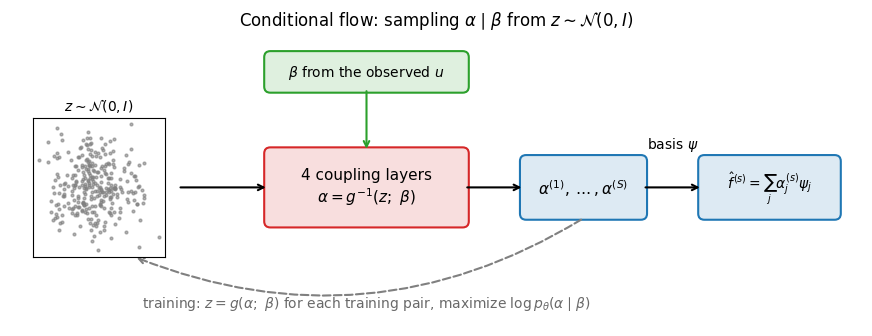

In [8]:
fig, ax = blank((11, 3.8), (0, 11), (0, 3.8), r"Conditional flow: sampling $\alpha \mid \beta$ from $z \sim \mathcal{N}(0, I)$")
inset = ax.inset_axes([0.3, 0.9, 1.7, 1.8], transform=ax.transData)
z_demo = rng.standard_normal((300, 2))
inset.scatter(z_demo[:, 0], z_demo[:, 1], s=4, color="gray", alpha=0.6)
inset.set_xticks([])
inset.set_yticks([])
inset.set_title(r"$z \sim \mathcal{N}(0, I)$", fontsize=10)
box(ax, 4.6, 1.8, 2.6, 1.0, "4 coupling layers\n" + r"$\alpha = g^{-1}(z;\ \beta)$", "tab:red")
box(ax, 4.6, 3.3, 2.6, 0.5, r"$\beta$ from the observed $u$", "tab:green", fontsize=10)
box(ax, 7.4, 1.8, 1.6, 0.8, r"$\alpha^{(1)}, \dots, \alpha^{(S)}$", "tab:blue")
box(ax, 9.8, 1.8, 1.8, 0.8, r"$\hat f^{(s)} = \sum_j \alpha^{(s)}_j \psi_j$", "tab:blue", fontsize=10)
arrow(ax, (2.2, 1.8), (3.3, 1.8))
arrow(ax, (4.6, 3.05), (4.6, 2.3), color="tab:green")
arrow(ax, (5.9, 1.8), (6.6, 1.8))
arrow(ax, (8.2, 1.8), (8.9, 1.8), r"basis $\psi$", dy=0.45)
ax.annotate("", xy=(1.6, 0.9), xytext=(7.4, 1.4), arrowprops=dict(arrowstyle="->", color="gray", lw=1.5, ls="--", connectionstyle="arc3,rad=-0.25"))
ax.text(4.6, 0.25, r"training: $z = g(\alpha;\ \beta)$ for each training pair, maximize $\log p_\theta(\alpha \mid \beta)$", ha="center", fontsize=10, color="dimgray")
plt.show()

In [9]:
n_samples, dequant = 50, 0.02
samples, flows = {}, {}
for p in "AB":
    b_n = norm_b[p](beta_tr[p])
    torch.manual_seed(0)
    flow = CouplingStack(k, d_cond=k, s_max=3.0)
    def nll(i):
        z, logdet = flow(a_n[i] + dequant * torch.randn(len(i), k), b_n[i])
        return (0.5 * (z ** 2).sum(1) - logdet).mean()
    t0 = time.time()
    loss = fit(flow, nll)
    with torch.no_grad():
        b_test = norm_b[p](beta_te[p])
        samples[p] = np.stack([unnorm_a(flow.inverse(torch.randn(n_test, k), b_test)) for _ in range(n_samples)])
    preds[p]["flow"] = samples[p].mean(0)
    flows[p] = flow
    print(f"Problem {p}, flow: final negative log-likelihood {loss:.2f}, {time.time() - t0:.1f} s")

Problem A, flow: final negative log-likelihood -26.91, 7.6 s


Problem B, flow: final negative log-likelihood -22.99, 7.5 s


Problem A, T = integration, 400 test functions, noise std 0.01 on u
model                      input error   re-simulation
noise in u                                    3.86e-02
linear                        3.26e-02        3.72e-02
MLP                           4.57e-02        5.05e-02
INN                           4.93e-02        4.49e-02
flow, mean of samples         3.80e-02        5.11e-02
flow, closest sample          2.91e-02        4.31e-02

Problem B, T = differentiation, 400 test functions, noise std 0.01 on u
model                      input error   re-simulation
noise in u                                    9.19e-04
linear                        4.68e-01        1.35e-02
MLP                           4.69e-01        3.98e-02
INN                           4.69e-01        4.64e-02
flow, mean of samples         4.69e-01        3.06e-02
flow, closest sample          3.19e-02        2.94e-02
true f with a_0 = 0           4.68e-01

test function 0: a_0 = 0.83


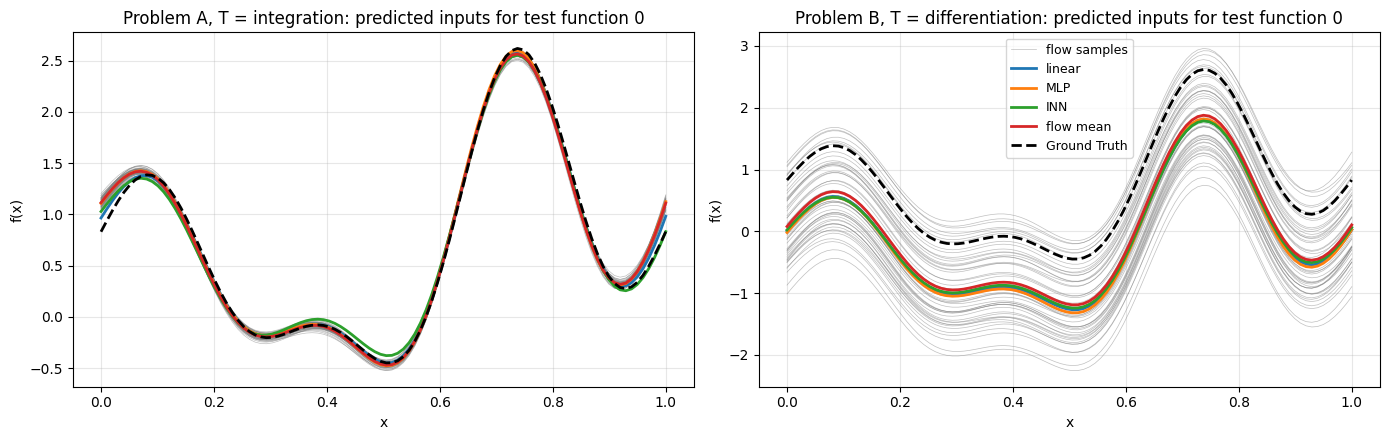

In [10]:
# T applied to each orthonormal input basis function, on the grid
x_fine = torch.linspace(0, 1, 10 * (m - 1) + 1)
with torch.no_grad():
    P_fine = encoders["f"](x_fine).numpy() @ np.linalg.inv(R["f"])
cumulative = np.vstack([np.zeros(k), np.cumsum((P_fine[1:] + P_fine[:-1]) / 2, axis=0) * (1 / (len(x_fine) - 1))])
x_grad = xt.clone().requires_grad_(True)
P_grad = encoders["f"](x_grad)
dP = torch.stack([torch.autograd.grad(P_grad[:, i].sum(), x_grad, retain_graph=True)[0] for i in range(k)], 1)
T_basis = {"A": cumulative[::10], "B": dP.detach().numpy() @ np.linalg.inv(R["f"])}

def errors(p, alpha):
    """Mean relative L2 errors of f_hat against f and of T f_hat against the observed u."""
    e_in = np.linalg.norm(f_hat(alpha) - f_te, axis=1) / np.linalg.norm(f_te, axis=1)
    e_re = np.linalg.norm(alpha @ T_basis[p].T - u_obs[p], axis=1) / np.linalg.norm(u_obs[p], axis=1)
    return e_in, e_re

names = {"A": "Problem A, T = integration", "B": "Problem B, T = differentiation"}
for p in "AB":
    print(f"{names[p]}, {n_test} test functions, noise std {sigma} on u")
    print(f"{'model':24s}{'input error':>14s}{'re-simulation':>16s}")
    noise = np.mean(np.linalg.norm(u_obs[p] - u_true[p], axis=1) / np.linalg.norm(u_obs[p], axis=1))
    print(f"{'noise in u':24s}{'':>14s}{noise:16.2e}")
    for name in ["linear", "MLP", "INN"]:
        e_in, e_re = errors(p, preds[p][name])
        print(f"{name:24s}{e_in.mean():14.2e}{e_re.mean():16.2e}")
    per_sample = [errors(p, samples[p][s]) for s in range(n_samples)]
    e_in_s = np.array([e[0] for e in per_sample])
    e_re_s = np.array([e[1] for e in per_sample])
    print(f"{'flow, mean of samples':24s}{errors(p, preds[p]['flow'])[0].mean():14.2e}{e_re_s.mean():16.2e}")
    best = e_in_s.argmin(0)
    print(f"{'flow, closest sample':24s}{e_in_s.min(0).mean():14.2e}{e_re_s[best, np.arange(n_test)].mean():16.2e}")
    if p == "B":
        print(f"{'true f with a_0 = 0':24s}{rel(f_te - a_te[:, :1], f_te):14.2e}")
    print()

n_star = int(np.argmax(a_te[:, 0] > 0.7))
print(f"test function {n_star}: a_0 = {a_te[n_star, 0]:.2f}")
colors = {"linear": "tab:blue", "MLP": "tab:orange", "INN": "tab:green", "flow": "tab:red"}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, p in zip(axes, "AB"):
    for s in range(n_samples):
        ax.plot(x, f_hat(samples[p][s, n_star]), color="gray", lw=0.5, alpha=0.5, label="flow samples" if s == 0 else None)
    for name, c in colors.items():
        ax.plot(x, f_hat(preds[p][name][n_star]), color=c, lw=2, label=name + (" mean" if name == "flow" else ""))
    ax.plot(x, f_te[n_star], "k--", lw=2, label="Ground Truth")
    ax.set_title(f"{names[p]}: predicted inputs for test function {n_star}")
    ax.set_xlabel("x")
    ax.set_ylabel("f(x)")
    ax.grid(True, alpha=0.3)
axes[1].legend(fontsize=9)
plt.tight_layout()
plt.show()

## The line of consistent inputs

The figure below places each predicted input of Problem B at its coordinates $(a_0, a_1)$ in the generating functions $1, \sin(\pi x), \dots, \sin(6 \pi x)$, a linear function of $\alpha$.
The inputs with the same $f'$ as the test function differ only in $a_0$, so they form the dotted horizontal line through the true input.
The forward map collapses this line to one point, and the inverse of that point is the whole line.

Problem B, flow: std of a_0 over 50 samples, mean over test functions 0.559 (uniform on [-1, 1]: 0.577)
Problem B, flow: true a_0 inside the range of the samples for 391 of 400 test functions


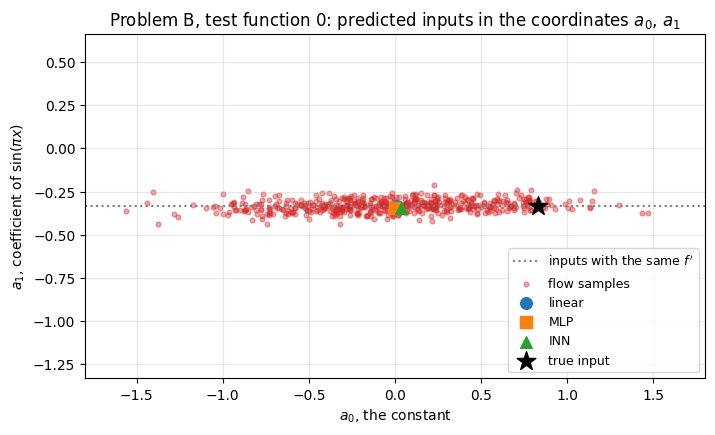

test function 0: true (a_0, a_1) = (0.83, -0.33); flow samples a_0 from -1.56 to 1.47; linear a_0 = 0.01, MLP a_0 = -0.00, INN a_0 = 0.04
total run time 56 s


In [11]:
# coordinates (a_0, a_1) of a predicted f_hat in the generating functions 1, sin(pi x), ..., sin(6 pi x)
to_a = lambda alpha: np.linalg.lstsq(E, f_hat(np.atleast_2d(alpha)).T, rcond=None)[0][:2].T
a0_samples = np.stack([to_a(samples["B"][s])[:, 0] for s in range(n_samples)])      # (n_samples, n_test)
inside = (a_te[:, 0] >= a0_samples.min(0)) & (a_te[:, 0] <= a0_samples.max(0))
print(f"Problem B, flow: std of a_0 over {n_samples} samples, mean over test functions {a0_samples.std(0).mean():.3f} (uniform on [-1, 1]: {1 / np.sqrt(3):.3f})")
print(f"Problem B, flow: true a_0 inside the range of the samples for {inside.sum()} of {n_test} test functions")

torch.manual_seed(1)
with torch.no_grad():
    b_star = norm_b["B"](beta_te["B"][n_star:n_star + 1]).repeat(500, 1)
    cloud = to_a(unnorm_a(flows["B"].inverse(torch.randn(500, k), b_star)))
a_true = a_te[n_star, :2]
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.axhline(a_true[1], color="gray", ls=":", lw=1.5, label="inputs with the same $f'$")
ax.scatter(cloud[:, 0], cloud[:, 1], s=12, color="tab:red", alpha=0.4, label="flow samples")
for name, marker in [("linear", "o"), ("MLP", "s"), ("INN", "^")]:
    pa = to_a(preds["B"][name][n_star])[0]
    ax.scatter(pa[0], pa[1], s=70, marker=marker, color=colors[name], label=name, zorder=5)
ax.scatter(a_true[0], a_true[1], s=200, marker="*", color="black", label="true input", zorder=6)
ax.set_title(f"Problem B, test function {n_star}: predicted inputs in the coordinates $a_0$, $a_1$")
ax.set_xlabel("$a_0$, the constant")
ax.set_ylabel("$a_1$, coefficient of $\\sin(\\pi x)$")
ax.set_xlim(-1.8, 1.8)
ax.set_ylim(a_true[1] - 1.0, a_true[1] + 1.0)
ax.set_aspect("equal")    # same scale on both axes, so the cloud shows its true shape
ax.grid(True, alpha=0.3)
ax.legend(fontsize=9, loc="lower right")
plt.show()
print(f"test function {n_star}: true (a_0, a_1) = ({a_true[0]:.2f}, {a_true[1]:.2f}); flow samples a_0 from {cloud[:, 0].min():.2f} to {cloud[:, 0].max():.2f}; "
      + ", ".join(f"{name} a_0 = {to_a(preds['B'][name][n_star])[0, 0]:.2f}" for name in ["linear", "MLP", "INN"]))
print(f"total run time {time.time() - t_start:.0f} s")

## What the two tables show

On Problem A every model recovers $f$, and the linear inverse has the lowest input error, $3.26 \times 10^{-2}$, against $4.57 \times 10^{-2}$ for the MLP, $4.93 \times 10^{-2}$ for the INN, and $3.80 \times 10^{-2}$ for the flow mean.
The linear error matches the noise amplification 0.032 predicted from the singular values, and every re-simulation error lies between $3.72 \times 10^{-2}$ and $5.11 \times 10^{-2}$, near the noise level $3.86 \times 10^{-2}$.
The INN undoes its own forward pass to $1.0 \times 10^{-14}$, which is roundoff.

On Problem B the linear model, the MLP, the INN, and the flow mean all have input errors of $4.68 \times 10^{-1}$ or $4.69 \times 10^{-1}$, the value $4.68 \times 10^{-1}$ of the true $f$ with $a_0$ set to 0.
Their re-simulation errors run from $1.35 \times 10^{-2}$ to $4.64 \times 10^{-2}$, so each prediction explains the observed $f'$ with the wrong constant.
The INN fits the forward direction to $3.74 \times 10^{-3}$ and the inverse direction only to $1.28 \times 10^{-1}$, because a bijection cannot send the line of constants to one point.
The flow samples spread along that line, with a standard deviation of $a_0$ of 0.559 against 0.577 for the uniform distribution on $[-1, 1]$.
The range of the 50 samples contains the true $a_0$ for 391 of the 400 test functions, and the closest sample has input error $3.19 \times 10^{-2}$.
Some samples fall outside $[-1, 1]$, from $-1.56$ to $1.47$ in the 500 samples of the figure, so the flow learns the line and approximates the distribution along it.
Choosing the right constant needs information that $f'$ does not hold, such as one value of $f$.